# Advanced AI IDS (CIC-IDS2017) with Visualization

In [34]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [26]:
warnings.filterwarnings("ignore")

## Load and Merge Dataset

In [2]:
data_folder = "CIC-IDS2017"  # change path

csv_files = [f for f in os.listdir(data_folder) if f.endswith(".csv")]

df_list = []
for file in csv_files:
    temp_df = pd.read_csv(os.path.join(data_folder, file), low_memory=False)
    df_list.append(temp_df)

df = pd.concat(df_list, ignore_index=True)

# Clean column names
df.columns = df.columns.str.strip()

print("Shape:", df.shape)
df.head()


Shape: (2830743, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


## Dataset Visualization

Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


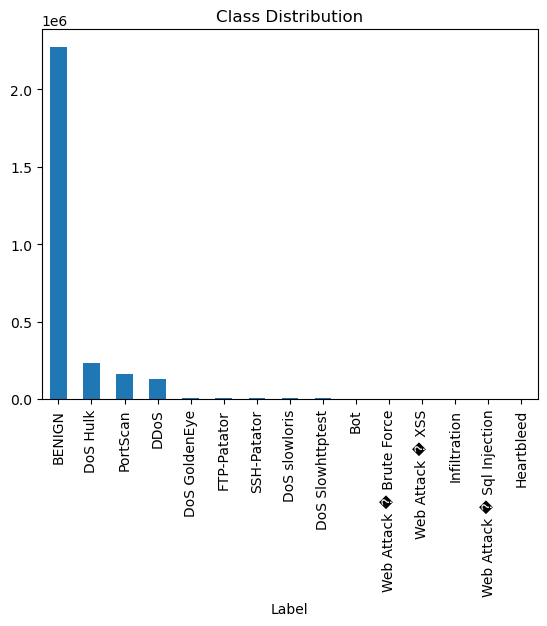

In [3]:
print(df['Label'].value_counts())

df['Label'].value_counts().plot(kind='bar')
plt.title("Class Distribution")
plt.show()


## Missing Values

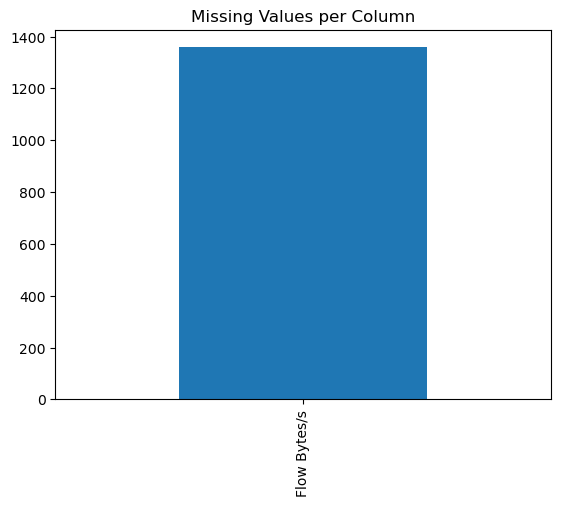

In [4]:
missing = df.isnull().sum()
missing = missing[missing > 0]

missing.plot(kind='bar')
plt.title("Missing Values per Column")
plt.show()


## Data Cleaning

In [5]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

print("After cleaning:", df.shape)


After cleaning: (2827876, 79)


## Outliers Visualization & Cleaning (Example Feature Visualization)

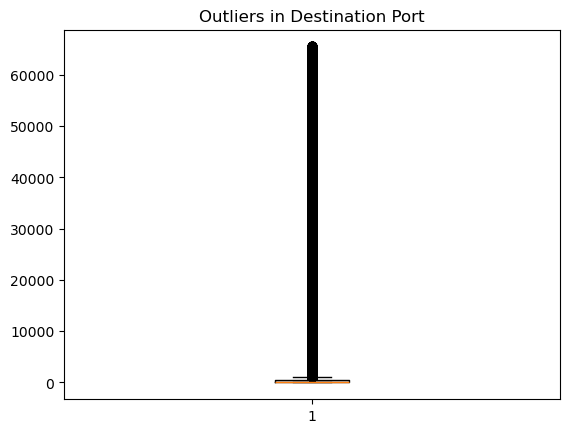

In [6]:
feature = df.select_dtypes(include=[np.number]).columns[0]

plt.boxplot(df[feature])
plt.title(f"Outliers in {feature}")
plt.show()


In [12]:
def remove_outliers_iqr(df, columns):
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        df = df[(df[col] >= lower) & (df[col] <= upper)]
    
    return df

# Apply only on numeric features
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

df = remove_outliers_iqr(df, numeric_cols)

print("After outlier removal:", df.shape)

After outlier removal: (328770, 79)


## Encoding Labels

In [13]:
le = LabelEncoder()
df['Label'] = le.fit_transform(df['Label'])

## Feature Scaling

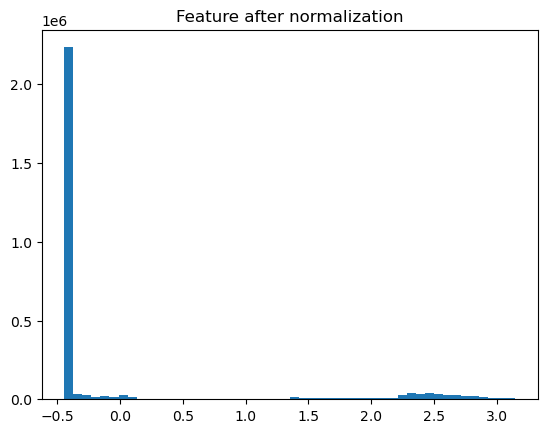

In [8]:
X = df.drop(columns=['Label'])
y = df['Label']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

plt.hist(X_scaled[:,0], bins=50)
plt.title("Feature after normalization")
plt.show()


## Train/Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)


## Model Training

In [10]:
model = RandomForestClassifier(n_estimators=100)
model.fit(X_train, y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Evaluation

Accuracy: 0.9985466144249402
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    454089
           1       0.92      0.70      0.80       386
           2       1.00      1.00      1.00     25588
           3       1.00      0.99      1.00      2055
           4       1.00      1.00      1.00     46259
           5       0.99      0.99      0.99      1103
           6       1.00      1.00      1.00      1146
           7       1.00      1.00      1.00      1570
           8       1.00      1.00      1.00         3
           9       1.00      1.00      1.00         5
          10       0.99      1.00      0.99     31712
          11       1.00      1.00      1.00      1242
          12       0.74      0.83      0.78       291
          13       1.00      0.20      0.33         5
          14       0.38      0.23      0.29       122

    accuracy                           1.00    565576
   macro avg       0.93      0.86      0.88    5655

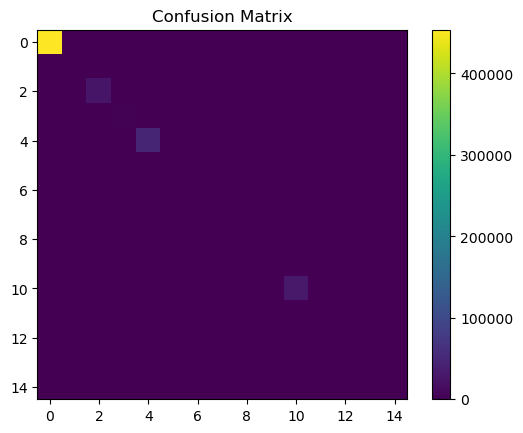

In [11]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.colorbar()
plt.show()


## Real Predictions Demo

In [18]:
print("=== REAL TRAFFIC PREDICTIONS ===\n")

sample = X_test[:10]
sample_labels = y_test[:10]

predictions = model.predict(sample)

label_map = {0: "BENIGN", 1: "ATTACK"}

pred_labels = [label_map.get(p, "UNKNOWN") for p in predictions]
true_labels = [label_map.get(t, "UNKNOWN") for t in sample_labels]

for i in range(len(sample)):
    print(f"Sample {i+1}")
    print(f"Actual: {true_labels[i]}")
    print(f"Predicted: {pred_labels[i]}")
    
    if pred_labels[i] == "BENIGN":
        print("➡️ SAFE TRAFFIC")
    else:
        print("➡️ 🚨 ATTACK DETECTED")
        
    print("-" * 40)

=== REAL TRAFFIC PREDICTIONS ===

Sample 1
Actual: BENIGN
Predicted: BENIGN
➡️ SAFE TRAFFIC
----------------------------------------
Sample 2
Actual: BENIGN
Predicted: BENIGN
➡️ SAFE TRAFFIC
----------------------------------------
Sample 3
Actual: BENIGN
Predicted: BENIGN
➡️ SAFE TRAFFIC
----------------------------------------
Sample 4
Actual: BENIGN
Predicted: BENIGN
➡️ SAFE TRAFFIC
----------------------------------------
Sample 5
Actual: BENIGN
Predicted: BENIGN
➡️ SAFE TRAFFIC
----------------------------------------
Sample 6
Actual: BENIGN
Predicted: BENIGN
➡️ SAFE TRAFFIC
----------------------------------------
Sample 7
Actual: BENIGN
Predicted: BENIGN
➡️ SAFE TRAFFIC
----------------------------------------
Sample 8
Actual: BENIGN
Predicted: BENIGN
➡️ SAFE TRAFFIC
----------------------------------------
Sample 9
Actual: BENIGN
Predicted: BENIGN
➡️ SAFE TRAFFIC
----------------------------------------
Sample 10
Actual: UNKNOWN
Predicted: UNKNOWN
➡️ 🚨 ATTACK DETECTED
---------

## IDS Simulation Function

In [27]:
def ids_predict(sample_input):
    sample_scaled = scaler.transform([sample_input])
    pred = model.predict(sample_scaled)
    label = le.inverse_transform(pred)[0]

    if label == "BENIGN":
        return "✅ SAFE"
    else:
        return "🚨 ATTACK"

# Test it
print("\n=== IDS SIMULATION ===")
test_sample = X.iloc[50].values
print("Prediction:", ids_predict(test_sample))


=== IDS SIMULATION ===
Prediction: 🚨 ATTACK


## Confidence Level

In [28]:
print("\n=== PREDICTION CONFIDENCE ===")

probs = model.predict_proba(sample)

for i in range(len(sample)):
    confidence = probs[i].max()
    print(f"Sample {i+1} confidence: {confidence:.2f}")


=== PREDICTION CONFIDENCE ===
Sample 1 confidence: 1.00
Sample 2 confidence: 1.00
Sample 3 confidence: 1.00
Sample 4 confidence: 1.00
Sample 5 confidence: 1.00
Sample 6 confidence: 1.00
Sample 7 confidence: 1.00
Sample 8 confidence: 1.00
Sample 9 confidence: 1.00
Sample 10 confidence: 1.00


## Confusion Matrix Explanation


=== MODEL INTERPRETATION ===
Confusion Matrix Shape: (15, 15)
✅ Correct predictions: 564754
❌ Incorrect predictions: 822
🎯 Accuracy: 0.9985


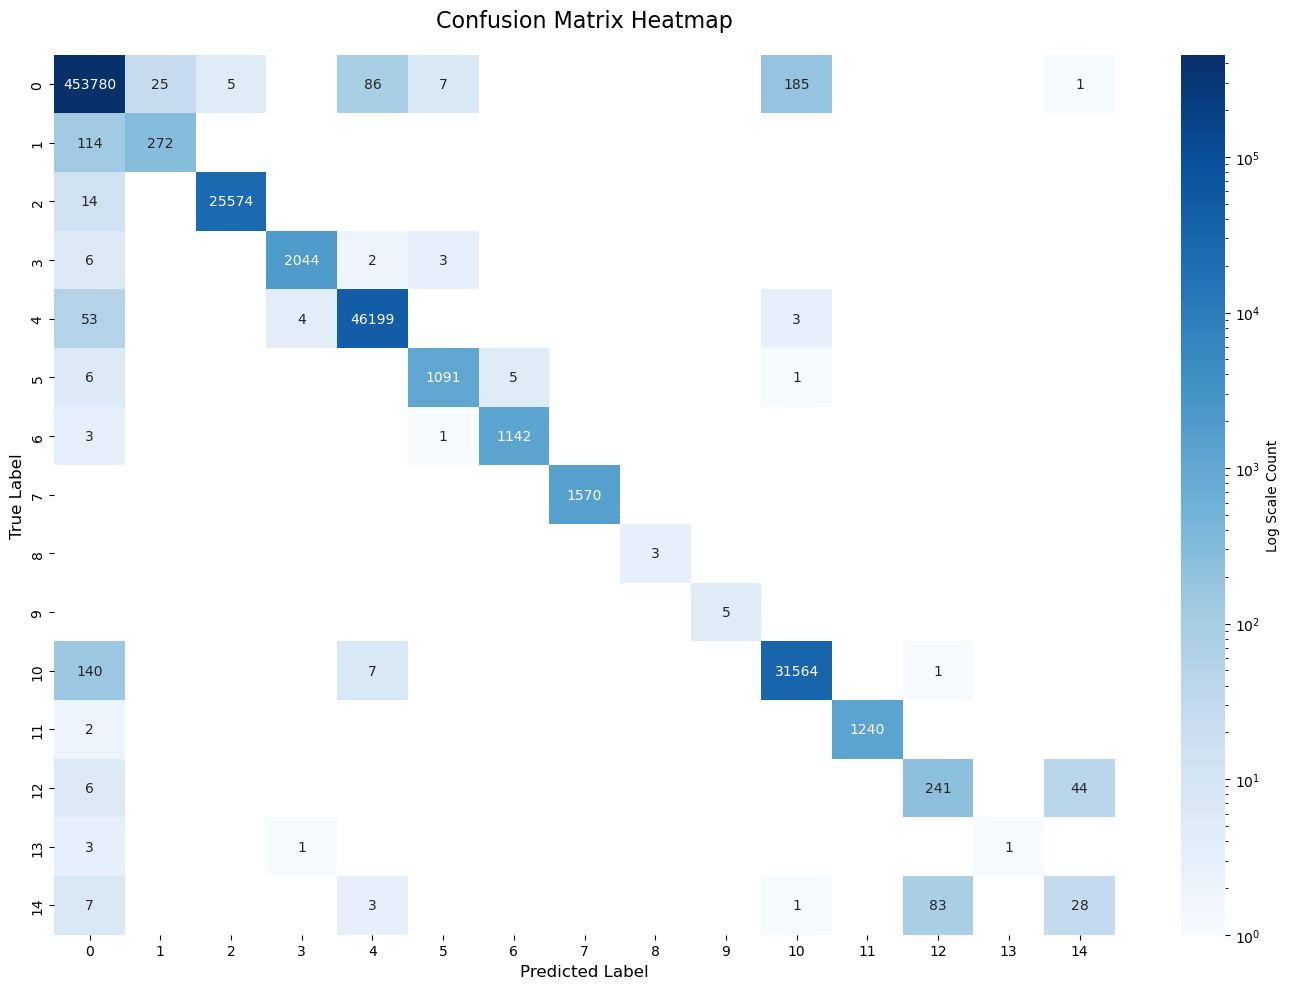

In [35]:
print("\n=== MODEL INTERPRETATION ===")
print("Confusion Matrix Shape:", cm.shape)

correct = cm.diagonal().sum()
total = cm.sum()
accuracy = correct / total

print(f"✅ Correct predictions: {correct}")
print(f"❌ Incorrect predictions: {total - correct}")
print(f"🎯 Accuracy: {accuracy:.4f}")

# --- VISUALIZATION ---

plt.figure(figsize=(14, 10))

# Create the heatmap
# Note: We use LogNorm for the color mapping because the huge difference 
# between 453,780 and 1 will make the standard colors useless.
sns.heatmap(
    cm, 
    annot=True,          # Show the numbers inside the squares
    fmt='g',             # 'g' format avoids scientific notation for large integers
    cmap='Blues',        # Blue color scale
    norm=LogNorm(),      # Logarithmic scale highlights small numbers (errors) against massive true positives
    cbar_kws={'label': 'Log Scale Count'}
)

plt.title('Confusion Matrix Heatmap', fontsize=16, pad=20)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

## Save for Deployment

In [31]:
import joblib

joblib.dump(model, "ids_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("\nModel and scaler saved → ready for deployment 🚀")


Model and scaler saved → ready for deployment 🚀
